### Hyperparameters:
- **Learning rate schedule**: $\eta = \frac{t_0}{t + t_1}$
  - $t_0 = 100$
  - $t_1 = 5000$
- **Regularization parameter**: $\lambda = 0.0001$
- **Degree of polynomial features (M)**: 9
- **Number of epochs**: 5000

In [1]:
M = 9
n_epochs = 5000
lambda_reg = 0.0001
t0 = 100
t1 = 5000

#Datasetup
n_samples=25
std = 0.15

### Create Dataset

In [2]:
import matplotlib.pyplot as plt
import torch

torch.manual_seed(42)

def create_toy_data(func, sample_size, std, domain=[0, 1]):
    x = torch.linspace(domain[0], domain[1], sample_size)
    y = func(x) + torch.randn(x.shape) * std
    return x.reshape(-1,1), y.reshape(-1,1)

def sinusoidal(x):
    return torch.sin(2 * torch.pi * x)

def polynomial_features(x, degree):
    x_poly = torch.cat([x**i for i in range(1, degree + 1)], dim=1)
    return x_poly.type(torch.DoubleTensor)

def add_bias(X):
    bias = torch.ones((X.shape[0], 1))
    return torch.cat([bias, X], dim=1)


x_train, y_train = create_toy_data(sinusoidal, n_samples, std)

x_test = torch.linspace(0, 1, 100).reshape(-1, 1)
y_test = sinusoidal(x_test).reshape(-1, 1)

x_train_poly = polynomial_features(x_train, M)
x_test_poly = polynomial_features(x_test, M)

X_train_b = add_bias(x_train_poly)
X_test_b = add_bias(x_test_poly)



### Train

#### Gradient calculation:
1. **Prediction**:
   $$ \hat{y} = X \theta $$

2. **Mean Squared Error (MSE) gradient**:
   $$ \nabla_{\theta} J(\theta) = \frac{2}{m} X^T (X \theta - y) $$

3. **L1 regularization gradient**:
   $$ \nabla_{\theta} R(\theta) = \lambda \cdot \text{sign}(\theta) $$

4. **Total gradient (with regularization)**:
   $$ \nabla_{\theta} = \nabla_{\theta} J(\theta) + \nabla_{\theta} R(\theta) $$

#### Weight update equation:
$$ \theta = \theta - \eta \cdot \nabla_{\theta} $$


In [3]:
def learning_schedule(t, t0=t0, t1=t1):
    lr = t0 / (t + t1)
    return lr

def mse(xi, yi, theta):
    predictions = xi @ theta
    mse_loss = ((predictions - yi) ** 2).mean()
    return mse_loss

def calc_gradient(theta, x , y, lambda_reg):
    y_pred = torch.matmul(x, theta)
    mse_gradient = 2 * torch.matmul(x.T, (y_pred - y)) / len(y)

    #Calc regularization except for bias
    l1_gradient = torch.zeros_like(theta)
    l1_gradient[1:] = lambda_reg * torch.sign(theta[1:])

    return mse_gradient +  l1_gradient

last_loss = 1
theta_best = 0
losses_train = []
losses_test = []

n = len(X_train_b)
theta = torch.randn(X_train_b.shape[1], 1, dtype=torch.double, requires_grad=False)

for epoch in range(n_epochs):
    for iteration in range(n):
        random_index = torch.randint(n, (1,))
        xi = X_train_b[random_index:random_index + 1]
        yi = y_train[random_index:random_index + 1]
        gradients = calc_gradient(theta, xi, yi, lambda_reg)

        eta = learning_schedule(epoch * n + iteration)

        theta -= eta * gradients

    loss_train = mse(X_train_b, y_train, theta)
    losses_train.append(loss_train)

    loss_test = mse(X_test_b, y_test, theta)
    losses_test.append(loss_test)

    if(loss_train < last_loss):
        theta_best = theta
        last_loss = loss_train

### Results

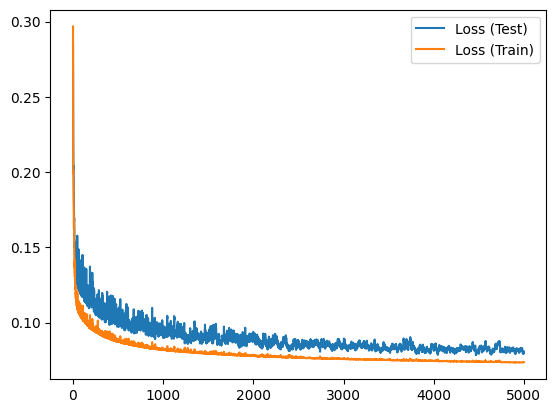

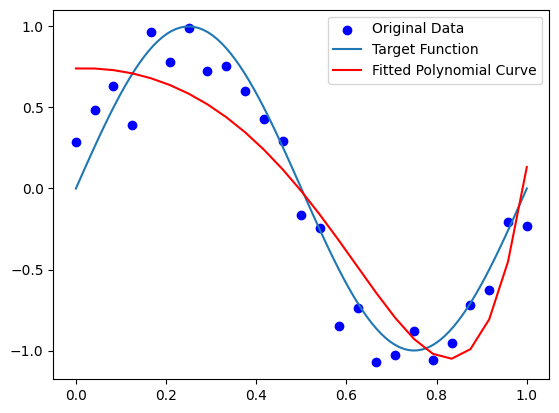

tensor([[ 0.7407],
        [ 0.1058],
        [-2.6982],
        [-0.4254],
        [-1.7107],
        [-0.1692],
        [ 0.4095],
        [ 2.2758],
        [ 1.2998],
        [ 0.3038]], dtype=torch.float64)


In [4]:
x = torch.linspace(1, n_epochs, n_epochs)
plt.plot(x, losses_test, label="Loss (Test)")
plt.plot(x, losses_train, label="Loss (Train)")
plt.legend()

plt.show()

x_np = x_train.numpy()
y_np = y_train.numpy()

y_pred = X_train_b @ theta_best

y_pred_np = y_pred.detach().numpy()

x_true = torch.linspace(0, 1, 100)
y_true = sinusoidal(x_true)

plt.scatter(x_np, y_np, color='blue', label='Original Data')
plt.plot(x_true, y_true, label="Target Function")
plt.plot(x_np, y_pred_np, color='red', label='Fitted Polynomial Curve')
plt.legend()
plt.show()

print(theta_best)